# Lesson 2.6: Expected Value and the Law of Large Numbers

Compute expected values for a die and for roulette, then watch the running average of simulated die rolls settle on 3.5 (the Law of Large Numbers).

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

## The question

A casino patron asks two questions. If I roll a fair die many times, what number should my average settle on? And if I place a $1 bet on a single number at roulette (it pays $35 and has 1 chance in 38), do I win or lose money in the long run? Can the expected value answer both, and can we watch a simulation settle onto it?

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## Step 1: Expected value of a die

E(X) is each outcome times its probability, added up. A die never shows 3.5, but 3.5 is where the average of many rolls ends up.

In [1]:
import numpy as np  # Load NumPy for arrays and fast arithmetic.

x = np.arange(1, 7)  # The outcomes of a die: the numbers 1 to 6.
p = np.full(6, 1 / 6)  # Each outcome has probability 1/6. np.full repeats that value six times.

print('x * P(x):', (x * p).round(4))  # Print each outcome times its probability, the pieces of the expected value.
print('E(X) =', round((x * p).sum(), 4))  # Add the pieces. The expected value is the sum of outcome times probability.

x * P(x): [0.1667 0.3333 0.5    0.6667 0.8333 1.    ]
E(X) = 3.5


**What this means.** The six pieces are 0.1667, 0.3333, 0.5, 0.6667, 0.8333 and 1.0, and they add to E(X) = 3.5. A die never shows 3.5, but 3.5 is the long-run average of many rolls.

## Step 2: Is a bet worth taking?

A $1 roulette bet on one number wins $35 with probability 1/38 and loses $1 otherwise. A negative expected value means a long-run loss for the player: the house edge.

In [2]:
win, lose = 35, -1  # Win $35 or lose $1: the two possible outcomes of the roulette bet.
p_win = 1 / 38  # The chance of winning on one number is 1 in 38.

ev = win * p_win + lose * (1 - p_win)  # Expected gain: win times its probability plus loss times its probability.
print(f'expected gain per $1 bet = {ev:.4f}')  # Print the expected gain per $1 bet.
print(f'that is a loss of about {abs(ev) * 100:.1f} cents per dollar')  # Convert it into cents of loss per dollar, so it is easy to understand.

expected gain per $1 bet = -0.0526
that is a loss of about 5.3 cents per dollar


**What this means.** The expected gain is -0.0526 dollars per $1 bet, a loss of about 5.3 cents per dollar. A negative expected value means the player loses on average in the long run, which is the house edge.

## Step 3: Simulate and track the running average

We roll a die 5,000 times with a seeded generator. The running average after n rolls is the cumulative total divided by n. Early values jump around, later ones stay near 3.5.

In [3]:
rng = np.random.default_rng(42)  # Create a seeded generator so the simulation repeats.
rolls = rng.integers(1, 7, size=5000)  # Roll a die 5,000 times.
running = np.cumsum(rolls) / np.arange(1, 5001)  # Running average after n rolls: the cumulative total divided by the number of rolls so far.

for n in [5, 50, 500, 5000]:  # Check the running average at a few chosen points.
    print(f'after {n:>4} rolls: average = {running[n - 1]:.3f}')  # Print each running average for rolls 5, 50, 500 and 5000.

after    5 rolls: average = 3.200
after   50 rolls: average = 3.760
after  500 rolls: average = 3.452
after 5000 rolls: average = 3.487


**What this means.** After 5 rolls the average was 3.200, after 50 it was 3.760, after 500 it was 3.452 and after 5000 it was 3.487. The early values jump around, but they move toward the expected 3.5 as the rolls pile up. That is the Law of Large Numbers.

## Step 4: Draw the running average

The line wobbles wildly at first and then flattens onto the expected value. Individual rolls stay random; the average becomes predictable.

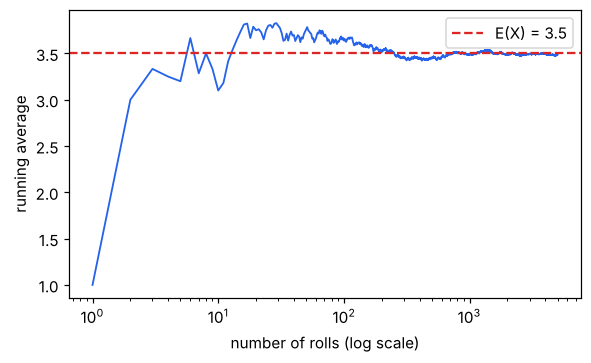

In [4]:
import matplotlib.pyplot as plt  # Load matplotlib, the plotting library.

plt.figure(figsize=(6, 3.4))  # Start a figure with a width and height that fit on a page.
plt.plot(np.arange(1, 5001), running, color='#2563eb', lw=1.2)  # Plot the running average against the number of rolls.
plt.axhline(3.5, color='#dc2626', ls='--', label='E(X) = 3.5')  # Add a dashed red line at the expected value 3.5 for comparison.
plt.xscale('log')  # Use a log scale on the x-axis so the early rolls are not squashed.
plt.xlabel('number of rolls (log scale)')  # Label the x-axis.
plt.ylabel('running average')  # Label the y-axis.
plt.legend()  # Show the legend so the dashed line is named.
plt.show()  # Display the figure.

**What this means.** The blue line wobbles wildly in the first few rolls and then flattens onto the dashed line at 3.5. Single rolls stay unpredictable, but the average of many becomes predictable.

## So, what is the answer?

The expected value of a die is 3.5, and the running average of 5,000 simulated rolls reached 3.487. The roulette bet has an expected value of -$0.0526 per $1, so a player loses about 5.3 cents per dollar in the long run. The caution: the expected value describes the long run, and a short run (even 50 rolls gave 3.760) can look very different.

## Now you try

At a school fair, a spinner game costs $3 to play. The spinner pays $10 with probability 0.1, pays $2 with probability 0.3, and pays nothing with probability 0.6. The organiser wants to know if the game makes money on average, and whether a simulation of many plays agrees.

**Data:** Prizes: [10, 2, 0] with probabilities [0.1, 0.3, 0.6]. Cost per play: 3. Simulate 20,000 plays with seed 5.

1. Find the expected prize and the expected net gain per play for the player.
2. Simulate 20,000 plays and compute the running average of the net gain.
3. Report the running average after 10, 100 and 20,000 plays. What does it show?

*Hint:* Expected value = sum of prize x probability, then subtract the cost. For the simulation use rng.choice(prize, size=20000, p=prob) and np.cumsum divided by the play number.

In [ ]:
# Your turn: write your code here


### Solution (try first, then peek)

In [ ]:
import numpy as np

prize = np.array([10, 2, 0])
prob = np.array([0.1, 0.3, 0.6])
cost = 3

ev_prize = (prize * prob).sum()
print(f'expected prize = {ev_prize:.2f}, expected net = {ev_prize - cost:.2f}')

rng = np.random.default_rng(5)
plays = rng.choice(prize, size=20_000, p=prob) - cost
running = np.cumsum(plays) / np.arange(1, 20_001)
for n in [10, 100, 20_000]:
    print(f'after {n:>6,} plays: average net = {running[n - 1]:.3f}')

expected prize = 1.60, expected net = -1.40
after     10 plays: average net = 0.400
after    100 plays: average net = -1.360
after 20,000 plays: average net = -1.384


**Answer.** The expected prize is $1.60, so the expected net gain is $1.60 - $3 = -$1.40 per play (the organiser gains $1.40 per play). The running average of the player's net gain was 0.400 after 10 plays, -1.360 after 100 and -1.384 after 20,000. The long-run average settles close to -1.40, while the first 10 plays happened to look profitable.

## The same question in R, SPSS and Stata

**R**

```r
x <- 1:6  # The six outcomes of a die.
sum(x * 1/6)                  # E(X) of a die  # Expected value: sum of outcome times 1/6.
35 * (1/38) + (-1) * (37/38)  # roulette  # Roulette: win $35 with probability 1/38, lose $1 with probability 37/38.

set.seed(42)  # Fix the seed.
rolls <- sample(6, 5000, replace = TRUE)  # Roll the die 5,000 times, with replacement.
cumsum(rolls)[c(5, 50, 500, 5000)] / c(5, 50, 500, 5000)  # Running average at rolls 5, 50, 500 and 5000: running totals divided by the counts.
```

How to read it: Check the first two results: 3.5 and -0.0526, which are exact and match Python. The last line gives four running averages that should drift toward 3.5 but will not be identical to Python's.

**SPSS** (Transform > Compute Variable (expected values); Analyze > Descriptive Statistics > Descriptives (the simulated mean))

```
SET SEED=42.
INPUT PROGRAM.
LOOP #i = 1 TO 5000.
COMPUTE roll = TRUNC(RV.UNIFORM(1, 7)).
END CASE.
END LOOP.
END FILE.
END INPUT PROGRAM.
DESCRIPTIVES VARIABLES=roll.
COMPUTE ev_die = (1+2+3+4+5+6)/6.
COMPUTE roulette = 35/38 - 37/38.
FORMATS ev_die roulette (F8.4).
LIST VARIABLES=ev_die roulette /CASES=FROM 1 TO 1.
```

How to read it: In the Descriptive Statistics table, the Mean of roll should be close to 3.5. LIST shows ev_die 3.5000 and roulette -0.0526. The exact values match Python's; the simulated mean is close, not identical.

**Stata**

```
display (1+2+3+4+5+6)/6
display 35/38 - 37/38

clear
set seed 42
set obs 5000
gen roll = ceil(6*runiform())
gen running = sum(roll) / _n
list running in 5
list running in 5000
summarize roll
```

How to read it: The first two lines print 3.5 and -.0526316, the exact values. The two list lines show the running average at roll 5 and at roll 5000, and the last summarize gives the mean of all rolls, near 3.5. The simulated values are close to Python's but not identical.